In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
np.random.seed(42)
random.seed(42)

from matplotlib.colors import LinearSegmentedColormap
grey_red = LinearSegmentedColormap.from_list("grey_red", ["lightgrey", "red"])
#hox_genes = sorted([g for g in sub3.var_names if g.startswith(("Hoxa", "Hoxb", "Hoxc", "Hoxd"))]); print(hox_genes)

In [2]:
adata=sc.read_h5ad('/home/julia/Trigem_reclust/both_branches.h5ad')

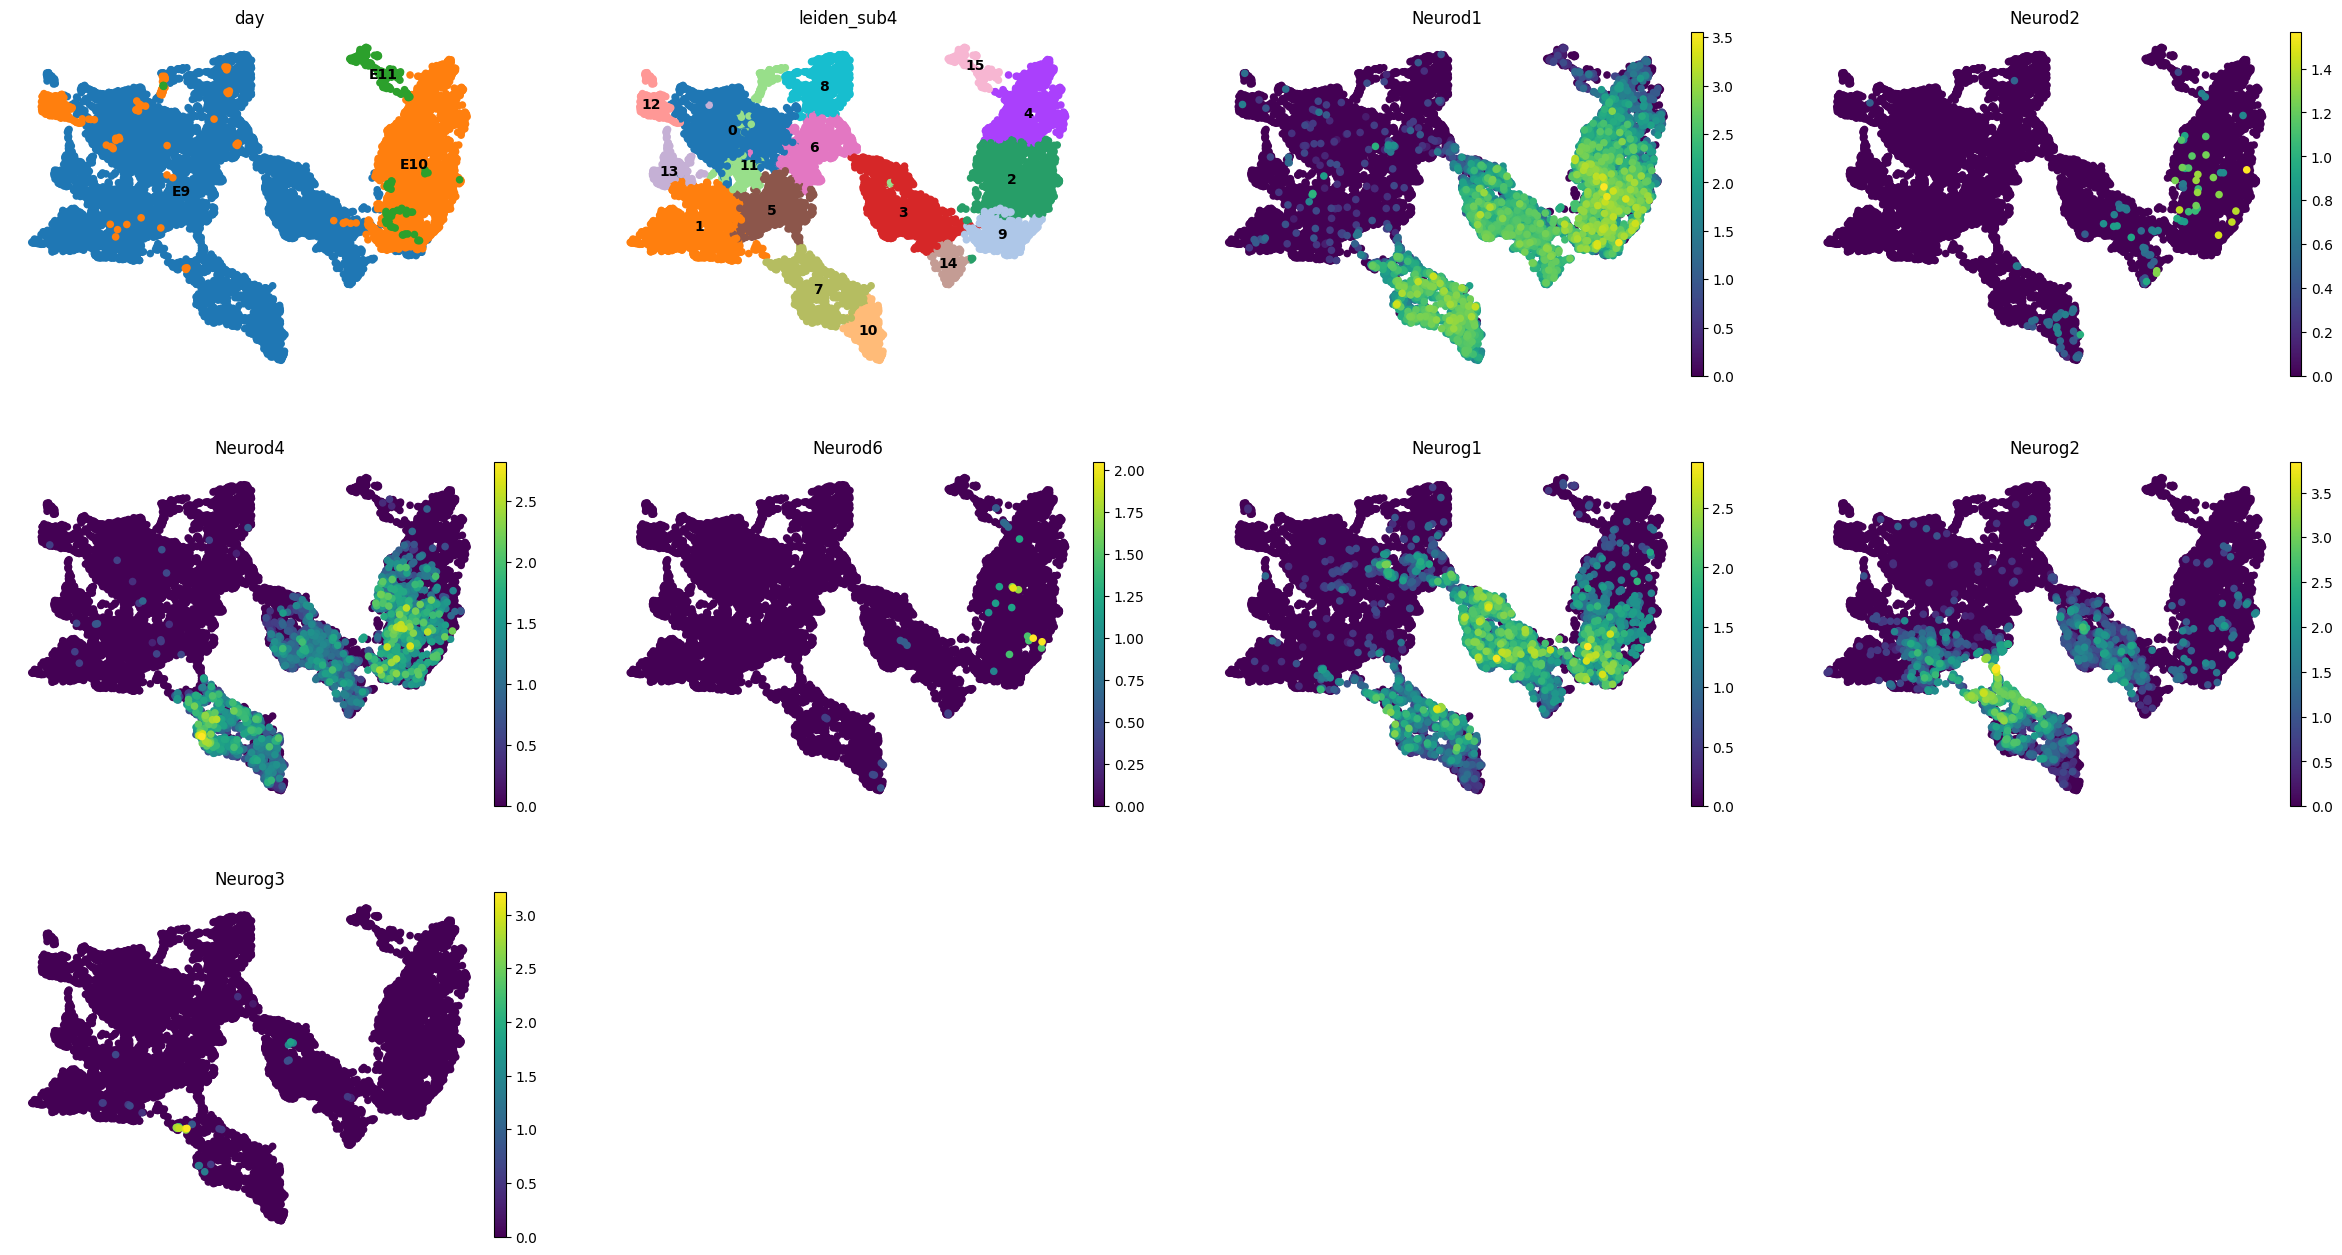

In [3]:
sc.pl.umap(adata, color=["day", "leiden_sub4",  'Neurod1', 'Neurod2', 'Neurod4', 'Neurod6', 'Neurog1', 'Neurog2', 'Neurog3'], size=120, frameon=False, legend_loc='on data')

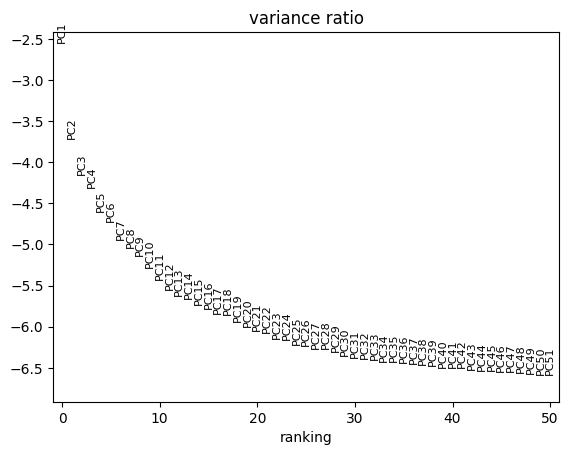

In [4]:
CLUSTERS = ["1", "5", "7", "10"]   # ← ваши кластеры
sub = adata[adata.obs["leiden_sub4"].isin(CLUSTERS)].copy()
sub.obs["leiden_parent"] = sub.obs["leiden_sub4"].astype(str)
#sc.pp.filter_genes(sub, min_cells=5)

sub.X = sub.layers["counts"].copy()
sc.pp.normalize_total(sub, target_sum=1e4)
sc.pp.log1p(sub)
sub.layers["lognorm"] = sub.X.copy()
sc.pp.highly_variable_genes(sub, flavor="seurat_v3", layer="counts", n_top_genes=3500)

# скейлинг + PCA во временной копии
tmp = sub[:, sub.var["highly_variable"]].copy()
sc.pp.scale(tmp, max_value=10)
sc.tl.pca(tmp, n_comps=70)
sc.pl.pca_variance_ratio(tmp, n_pcs=50, log=True)

sub.obsm["X_pca"] = tmp.obsm["X_pca"]
sub.uns["pca"] = tmp.uns["pca"]
del tmp

In [5]:
#sc.pp.neighbors(sub, n_pcs=30, n_neighbors=35)   # n_pcs по графику локтя
sc.tl.leiden(sub, resolution=0.2, key_added="leiden_sub_2")

/tmp/ipykernel_2596830/2974115883.py:2: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(sub, resolution=0.2, key_added="leiden_sub_2")


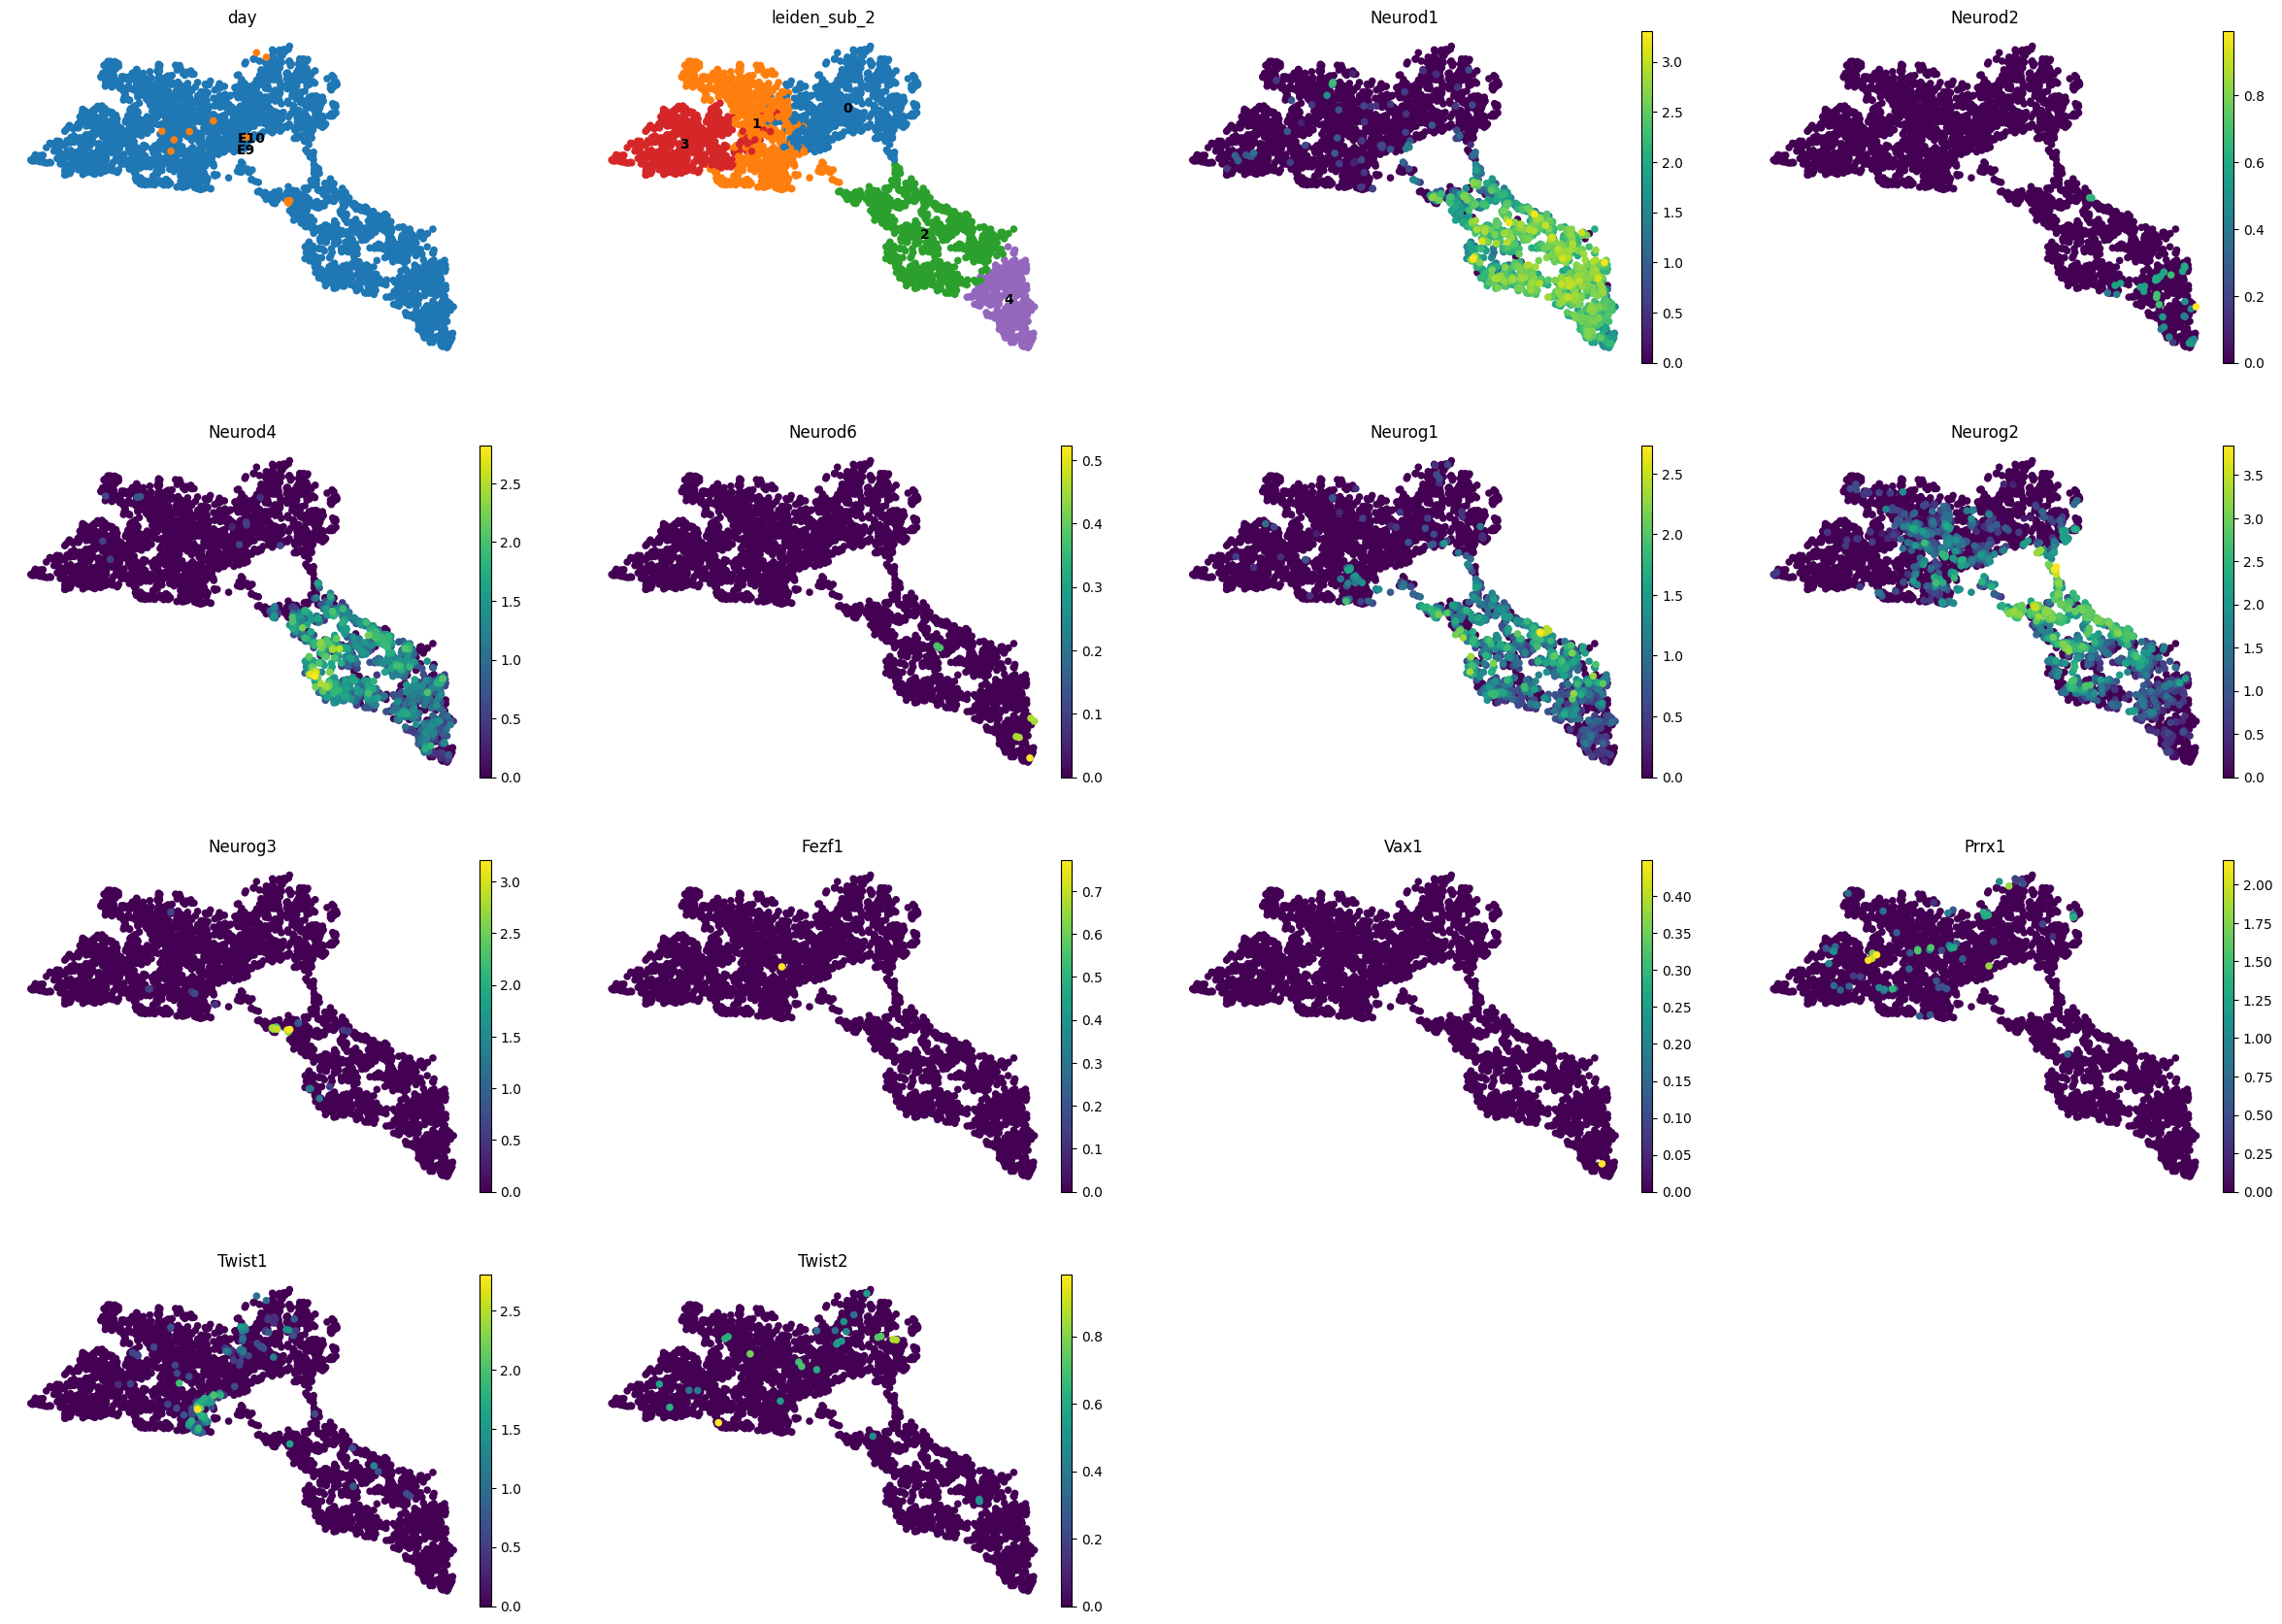

In [6]:
#sc.pp.neighbors(sub, n_pcs=30, n_neighbors=35)   # n_pcs по графику локтя
#sc.tl.leiden(sub, resolution=1.2, key_added="leiden_sub")
#sc.tl.umap(sub)
sc.pl.umap(sub, color=["day", 'leiden_sub_2',  'Neurod1', 'Neurod2', 'Neurod4', 'Neurod6', 'Neurog1', 'Neurog2', 'Neurog3', 'Fezf1', 'Vax1', 'Prrx1', 'Twist1', 'Twist2'], size=120, frameon=False, legend_loc='on data')

{'0': ['Bmp2', 'Ccbe1', 'Slc7a11', 'Bmper', 'A830082K12Rik', 'Tafa1', 'Pakap', 'Tinagl1', 'Trp63', 'Galnt16', 'Gdnf', 'Shb', 'Pcdh19', 'Arhgap23', 'Rgcc'], '1': ['Gsap', 'Hoxb1', 'Adarb2', 'Daam2', 'Etv1', 'Meox1', 'Pde11a', 'Masp1'], '2': ['Megf11', 'Tspan2', 'Gem', 'Iffo2', 'Minar2', 'Art1', 'Elk3', 'Alpl', 'Plcxd3'], '3': ['Pax1', 'Foxe1', 'Vgll2', 'Mid1ip1', 'Pmp22', 'Lypd6', 'Cxxc4', 'Pcgf5', 'Pdgfd', 'Edn1', 'Foxp2', 'Epha7', 'Col11a1', 'Slc35f3', 'Ryr2'], '4': ['Ina', 'Gm26871', 'Dlgap2', 'Rab6b', 'D930028M14Rik', 'Akap6', 'Prox2', 'Map6', 'Slc45a3', 'Rgs7', 'Dusp8', 'Rundc3a', 'Thsd7a', 'Xkr4', 'Kcne1l']}


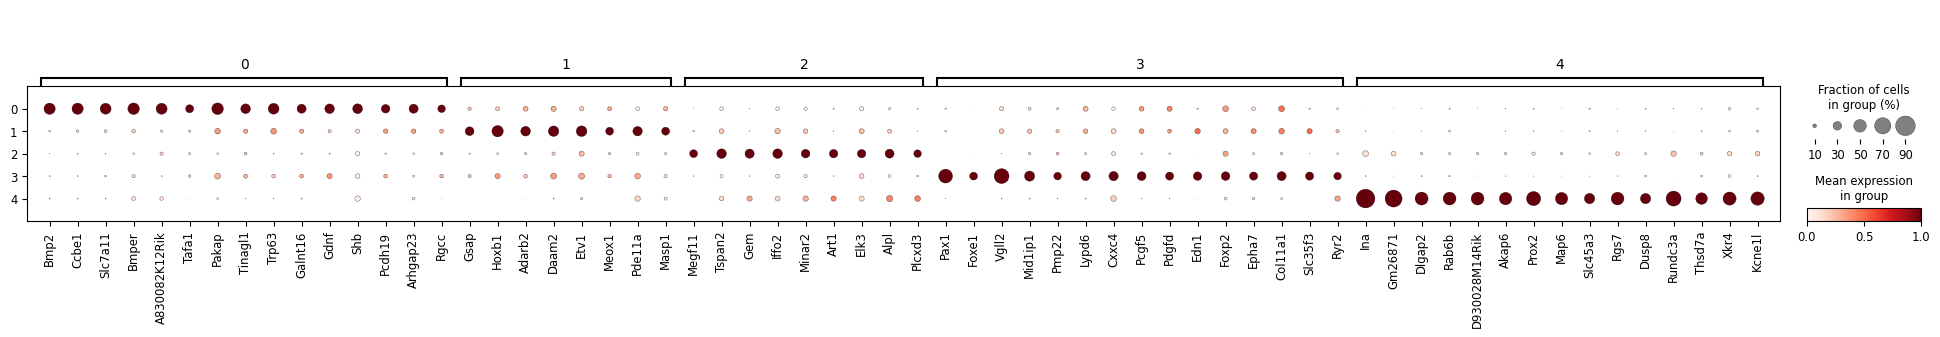

In [7]:
import numpy as np
import pandas as pd

groupby = "leiden_sub_2"
adata = sub                      # use log-normalized data in .X
groups = adata.obs[groupby].cat.categories

# per-cluster mean expression and fraction of expressing cells
means, fracs = {}, {}
for g in groups:
    Xi = adata[adata.obs[groupby] == g].X
    means[g] = np.asarray(Xi.mean(0)).ravel()
    fracs[g] = np.asarray((Xi > 0).mean(0)).ravel()
means = pd.DataFrame(means, index=adata.var_names)   # genes x clusters
fracs = pd.DataFrame(fracs, index=adata.var_names)

rows = []
for g in groups:
    others = [o for o in groups if o != g]
    frac_in  = fracs[g]
    frac_out = fracs[others].max(axis=1)              # worst competitor
    lfc      = np.log2((np.expm1(means[g]) + 1e-9) /
                       (np.expm1(means[others]).max(axis=1) + 1e-9))
    score = (frac_in - frac_out) * lfc.clip(lower=0)
    rows.append(pd.DataFrame({"cluster": g, "gene": adata.var_names,
                              "frac_in": frac_in.values, "frac_out_max": frac_out.values,
                              "lfc_vs_next": lfc.values, "score": score.values}))
spec = pd.concat(rows)

# filters: expressed in the cluster, mostly absent from every other cluster
spec = spec[(spec.frac_in >= 0.25) & (spec.frac_out_max <= 0.2) & (spec.lfc_vs_next >= 1)]

# each gene goes only to its best cluster
spec = spec.sort_values("score", ascending=False).drop_duplicates("gene")

n = 15
top = spec.groupby("cluster", observed=True).head(n).sort_values(["cluster", "score"], ascending=[True, False])
marker_dict = {c: d["gene"].tolist() for c, d in top.groupby("cluster", observed=True)}
print(marker_dict)

sc.pl.dotplot(adata, var_names=marker_dict, groupby=groupby,
              standard_scale="var", dendrogram=False)

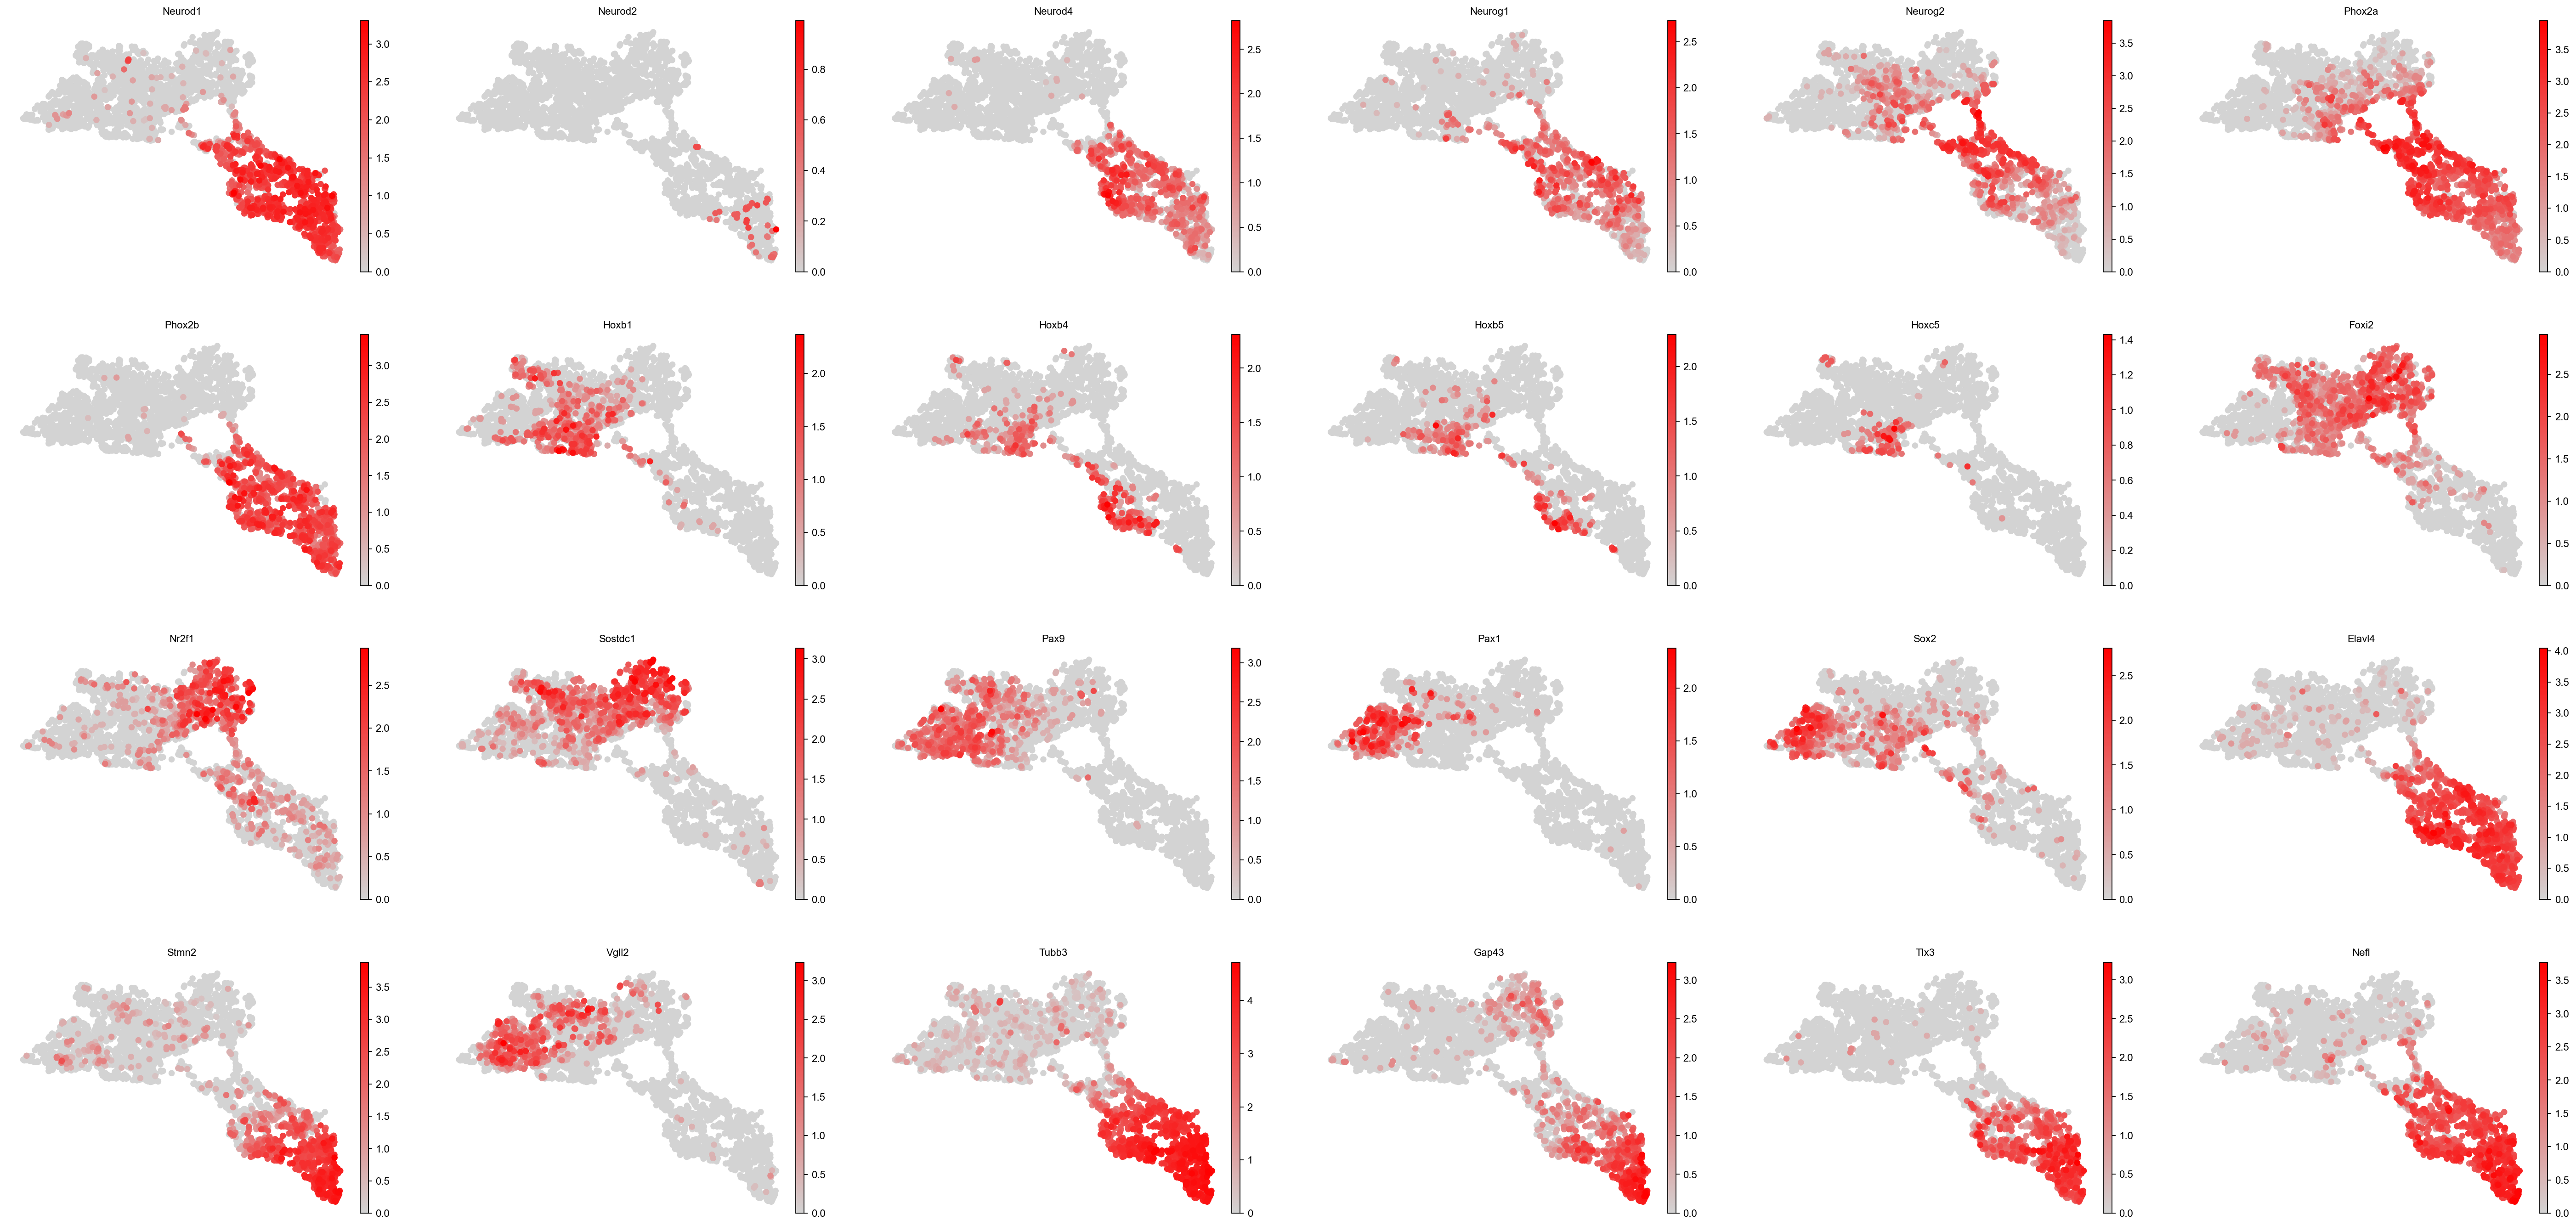

In [8]:
import matplotlib as mpl

sc.set_figure_params(vector_friendly=True, dpi_save=300, figsize=(6.4, 4.8), fontsize=10)
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42

sc.pl.umap(
    sub,
 color=['Neurod1', 'Neurod2', 'Neurod4',  'Neurog1', 'Neurog2', 'Phox2a', 'Phox2b', 'Hoxb1', 'Hoxb4', 'Hoxb5','Hoxc5' ,
                      'Foxi2', 'Nr2f1',
 'Sostdc1', 'Pax9','Pax1', 'Sox2','Elavl4','Stmn2', 'Vgll2',
 'Tubb3','Gap43', 'Tlx3', 'Nefl',],
    ncols=6,
    cmap=grey_red,
    size=150,
    frameon=False, 
save="_all_e10_11_11_2.svg",
)

In [9]:
sub.write('Epibranchial_petrosal.h5ad')